#### [PREV](5.OOP_KNN.ipynb) | [HOME](../README.md) | [NEXT](7.OOP_MLOps_Neural_Network_Intermediate.ipynb)

---

# Neural Network Linear Regression: Simple Approach

This Jupyter Notebook trains a very simple neural network model to perform Linear Regression. We will use the NESA Course Specifications Linear Regression dataset, which students are already familiar with, so they can focus on understanding the TensorFlow OOP Neural Network implementation.

#### Course Specifications

<figure>
    <center><img src="images/NN_Course-Specs.png" alt="Course Specs Neural Network image" width="500" />
    <figcaption><p><em>Source: Page 29 of the Software Engineering Course Specifications</em></p>
    </figcaption></center>
</figure>

Neural networks were designed to mimic the processing inside the human brain. They consist of a series of interconnected nodes (artificial neurones). Each neurone receives input signals, combines them using its weightings and bias, and can then pass a signal on to connected nodes.

In the diagram, signal strength between nodes with the strongest weightings are thicker representing a higher priority in determining the final output. The 'Bias' and 'Weightings' are learnt during the training cycle and used for predictions in the execution cycle.

#### Step 1: Import Dependencies

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '1' 
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import mean_absolute_error,mean_squared_error 

print(tf.__version__)

I0000 00:00:1794960984.515645    6982 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794960989.937415    6982 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


2.21.0


#### Step 2: Import The Data
We have extended the dataset to allow for test/training splitting.

In [2]:
# Import data as NumPy arrays
# Training features
X_feature = np.array([[-26], [-24], [-22], [-20], [-18], [-16], [-14], [-12], [-10], [-8], [-6], [-4], [-2], [0], [2], [4], [6], [8], [10], [12], [14], [16], [18], [20], [22], [24], [26]])

# Target variable
y_target = np.array([-27, -25, -23, -21, -19, -17, -15, -13, -11, -9, -7, -5, -3, -1, 1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21, 23, 25])


#### Step 3: Split The Data into Training And Testing Sets

In [3]:
# random_state makes the split the same every time the notebook is run
X_train, X_test, y_train, y_test = train_test_split(X_feature, y_target, test_size=0.2, random_state=42)

#### Step 4: Visualise The Data

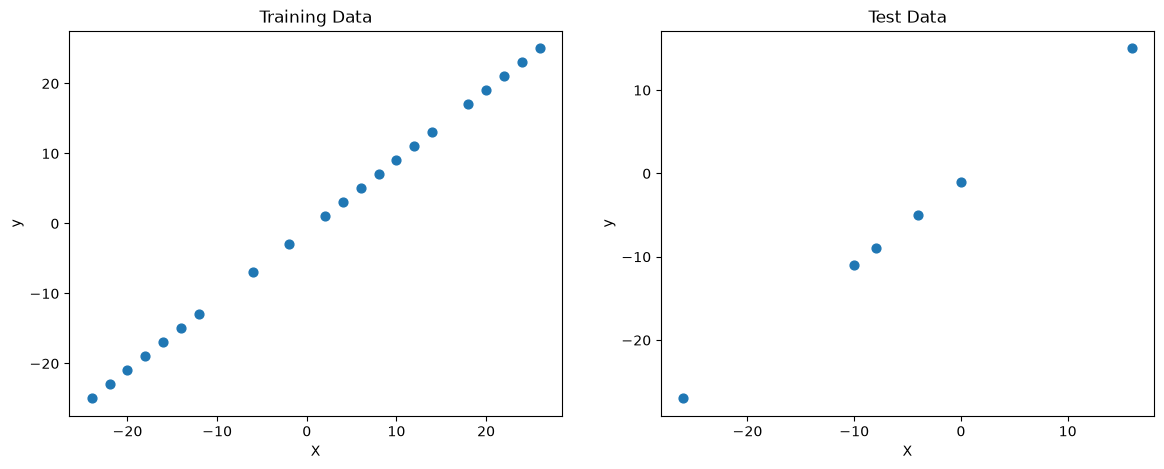

In [4]:
# Plot the training and test data
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

axs[0].scatter(X_train, y_train, s=40)
axs[0].set_title("Training Data")
axs[0].set_xlabel("X")
axs[0].set_ylabel("y")


axs[1].scatter(X_test, y_test, s=40)
axs[1].set_title("Test Data")
axs[1].set_xlabel("X")
axs[1].set_ylabel("y")
plt.show()

#### Step 5: Instantiate a Neural Network Object And Configure The Layers

The basic building block of a neural network is the [*layer*](https://www.tensorflow.org/api_docs/python/tf/keras/layers). Layers extract representations from the data fed into them. Hopefully, these representations are meaningful for the problem at hand.

Most of deep learning consists of chaining together simple layers. Most layers, such as `tf.keras.layers.Dense`, have parameters that are learned during training.

In [5]:
model = Sequential([
    Input(shape=(1,)),  # Input layer with 1 feature
    Dense(3),           # Hidden layer with 3 neurons
    Dense(1)            # Output layer with 1 neuron for regression
])

E0000 00:00:1794960994.184475    6982 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


#### About this model

The above code will instantiate a model (lines 1-5) with an input layer (line 2) that, in this case, takes in 1 feature. The model then has a hidden layer with 3 neurons (line 3). The model then has an output layer with 1 neuron (line 4) that will output a regression value. No activation function is set, so every neuron is linear, which suits this linear data. In training, the input data is passed forward and the error is passed backward in training cycles to find the optimal settings (see epochs below).

> [!Note]
>
> For binary classification the output layer usually has 1 neuron with a `sigmoid` activation. For multiclass classification it has $n$ neurons (one for each of the $n$ classes) with a `softmax` activation.

In [6]:
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mae'])

#### Step 6: Fit The Model

Fitting (Training) the neural network model requires the following steps:

1. Fit the training data to the model. In this example, the training data is in the `X_train` and `y_train` arrays.
2. The model learns to associate features and targets.
3. You ask the model to make predictions about a test set—in this example, the `X_test`.
4. Verify that the predictions match the targets from the `y_test` array.


In [7]:
# You can adjust the number of epochs and batch size based on your data and resources.
# verbose=2 prints one line per epoch
model.fit(X_train, y_train, epochs=200, batch_size=1, validation_split=0.2, verbose=2)

Epoch 1/200
16/16 - 1s - 59ms/step - loss: 63.0317 - mae: 7.0322 - val_loss: 24.1570 - val_mae: 4.2711
Epoch 2/200
16/16 - 0s - 5ms/step - loss: 52.7579 - mae: 6.4216 - val_loss: 20.7544 - val_mae: 3.9710
Epoch 3/200
16/16 - 0s - 5ms/step - loss: 43.5655 - mae: 5.8319 - val_loss: 17.7302 - val_mae: 3.6809
Epoch 4/200
16/16 - 0s - 5ms/step - loss: 36.2554 - mae: 5.2936 - val_loss: 14.7003 - val_mae: 3.3632
Epoch 5/200
16/16 - 0s - 5ms/step - loss: 29.1797 - mae: 4.7190 - val_loss: 12.2058 - val_mae: 3.0743
Epoch 6/200
16/16 - 0s - 5ms/step - loss: 22.9936 - mae: 4.1732 - val_loss: 10.2320 - val_mae: 2.8219
Epoch 7/200
16/16 - 0s - 9ms/step - loss: 18.7267 - mae: 3.7149 - val_loss: 8.2207 - val_mae: 2.5355
Epoch 8/200
16/16 - 0s - 8ms/step - loss: 14.1810 - mae: 3.2056 - val_loss: 6.7728 - val_mae: 2.3040
Epoch 9/200
16/16 - 0s - 5ms/step - loss: 10.9253 - mae: 2.7950 - val_loss: 5.5632 - val_mae: 2.0878
Epoch 10/200
16/16 - 0s - 5ms/step - loss: 8.3969 - mae: 2.4112 - val_loss: 4.5115 -

#### Training Cycle 

An $Epoch$ represents one complete training cycle of a neural network. During each $Epoch$, the network processes the entire training dataset once, adjusting its internal weights and biases. Initially, these weights and biases are set to random values. Using the training data (inputs with known outputs), the network applies forward propagation to make predictions and backward propagation to iteratively update the weights. This process minimises the error between predicted and actual outputs. With repeated epochs, the network's accuracy improves as it learns to recognise patterns in the data.

#### Step 7: Execution Cycle (Make Predictions)

The execution cycle follows the training cycle and utilises the optimal internal values developed during the training cycle to determine the output. With the model trained, you can use it to make predictions about new features.

In [8]:
# Predict the target for a new data point (X = 4)
new_X = np.array([[4]])

new_y = model.predict(new_X)
print(f"Predicted target for X = 4:\n{new_y}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step
Predicted target for X = 4:
[[3.0005612]]


> [!Important]
> Neural Network training is inherently [stochastic](https://en.wikipedia.org/wiki/Stochastic), the tuning of the neurons depends on the initialisation of the weights. So the result (the local minimum you end up in) depends on the initialisation too. This can be observed in the variance of this prediction after re-training the model.

#### Step 8: Plot the Predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step


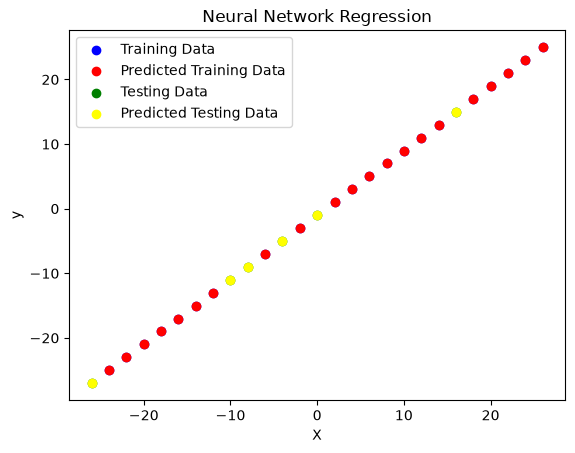

In [9]:
# Plot the actual data and model predictions
plt.scatter(X_train, y_train, label='Training Data', color='blue')
plt.scatter(X_train, model.predict(X_train), label='Predicted Training Data', color='red')
plt.scatter(X_test, y_test, label='Testing Data', color='green')
plt.scatter(X_test, model.predict(X_test), label='Predicted Testing Data', color='yellow')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()
plt.title('Neural Network Regression')
plt.show()

#### Step 9: Evaluate The Model

In [10]:
# Get evaluative data from the model using the testing data
model_eval = model.evaluate(X_test, y_test)
print(f"Model evaluation [loss (MSE), MAE]: {model_eval}")

test_predictions = model.predict(X_test).flatten()
mae = mean_absolute_error(y_true=y_test, y_pred=test_predictions)
mse = mean_squared_error(y_true=y_test, y_pred=test_predictions)
print("MAE:", mae)
print("MSE:", mse)
print()

# Manually calculate the loss and cost of the model
model_loss = pd.DataFrame({
    'Target': y_test,
    'Predicted result': test_predictions,
    'Loss': abs(y_test - test_predictions)
})
model_cost = model_loss['Loss'].mean()
print(f"The cost or average loss of this model is {model_cost:.5f}")
print(model_loss)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - loss: 5.1277e-07 - mae: 6.9372e-04
Model evaluation [loss (MSE), MAE]: [5.127745339450485e-07, 0.0006937186117284]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
MAE: 0.0006937186117284
MSE: 5.127745339450485e-07

The cost or average loss of this model is 0.00069
   Target  Predicted result      Loss
0     -11        -10.999239  0.000761
1      -1         -0.999382  0.000618
2      -9         -8.999269  0.000731
3      15         15.000391  0.000391
4     -27        -26.999014  0.000986
5      -5         -4.999325  0.000675
